### Good executions vs. tips for improvement: a video subspace from expert moment annotations

Experts marked moments of each take as **good executions** or **tips for improvement**
(`proficiency_demonstration_{train,val}.json`), each with a timestamp (where the expert paused the video) and
what they said. Here every moment becomes a pair: the zero-shot Qwen3.5-4B embedding of a short 1 FPS ego video
window around the timestamp (mostly before it), and the embedding of the moment's text tagged with its polarity
("Good execution: ..." / "Tip for improvement: ..."). CCA on the train pairs gives a video subspace; at test time
only video is used: each take is cut into windows of the same length, projected, averaged, and a probe predicts
proficiency. A "good minus tip" direction (from the polarity alone, no text, no proficiency labels) is the control.

Steps: (1) pick the window length on a subset of train takes, (2) embed every moment, (3) go/no-go: can the video
tell good from tip moments on held-out train takes at all, (4) embed every take as back-to-back windows,
(5) CCA, (6) proficiency probes, scored on all test takes and on subgroups.

Frame timestamps given to the model are relative to each window (0, 1, ... s), so every window of a given length has
the same prompt and the model can't see where in the take the window lies.

In [1]:
import ast
import json
from collections import Counter, defaultdict
from pathlib import Path

import av
import numpy as np

# Same takes as the earlier idea_1 notebooks: video and transcribed expert commentary, train / SkillFormer test split.
DATA_ROOT = next(
    p / "data" for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "annotations").is_dir()
)
ANNOTATION_ROOT = DATA_ROOT / "annotations"
COMMENTARY_ROOT = ANNOTATION_ROOT / "expert_commentary"
WINDOW_FPS = 1

LEVELS = {
    "Novice": 1,
    "Early Expert": 2,
    "Intermediate Expert": 3,
    "Late Expert": 4,
}

def take_name(m):
    return m["video_paths"]["ego"].split("/")[1]

def video_path(m):
    parts = m["video_paths"]["ego"].split("/")
    parts[-1:-1] = ["downscaled", "448"]
    return DATA_ROOT.joinpath(*parts)

def has_commentary(take):
    """Whether any expert recorded transcribed commentary on the take (the take set of the earlier notebooks)."""
    for data_path in (COMMENTARY_ROOT / take).rglob("data.json"):
        transcript_path = data_path.parent / "transcriptions.json"
        if not transcript_path.exists():
            continue
        data = json.loads(data_path.read_text(encoding="utf-8"))
        transcripts = json.loads(transcript_path.read_text(encoding="utf-8"))
        if any(transcripts.get(a.get("recording_path"), {}).get("text", "").strip() for a in data.get("annotations", [])):
            return True
    return False

def num_seconds(path):
    """Number of 1 FPS frames decode_1fps() gets from the video (frames 0, 30, 60, ... at 30 FPS)."""
    with av.open(str(path)) as container:
        stream = container.streams.video[0]
        step = round(float(stream.average_rate) / WINDOW_FPS)
        return (stream.frames - 1) // step + 1

with open("models/SkillFormer/annotation_test.jsonl", encoding="utf-8") as file:
    test_takes = {json.loads(line)["video_paths"][0].split("/")[1] for line in file}

def split_clips(split):
    annotation_file = "proficiency_demonstrator_train.json" if split == "train" else "proficiency_demonstrator_val.json"
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        metadata = json.load(file)["annotations"]
    clips = []
    for m in metadata:
        if split == "test" and take_name(m) not in test_takes:
            continue
        if not video_path(m).exists() or not has_commentary(take_name(m)):
            continue
        clips.append({"take_name": take_name(m), "scenario": m["scenario_name"], "score": LEVELS[m["proficiency_score"]],
                      "participant": m["origin_participant_id"], "video": str(video_path(m)),
                      "seconds": num_seconds(video_path(m))})
    return clips

clips_by_split = {split: split_clips(split) for split in ("train", "test")}
clips = clips_by_split["test"]
clip_of = {clip["take_name"]: clip for split_list in clips_by_split.values() for clip in split_list}
for split, split_list in clips_by_split.items():
    print(f"{split}: {len(split_list)} takes, {sum(c['seconds'] for c in split_list) / 3600:.1f} h of video")

# Good executions (polarity 1) and tips for improvement (polarity 0) of those takes. Each entry's "list" is a Python
# list literal of sentences (NaN for a few blank entries, which are dropped).
POLARITIES = {"good_executions": (1, "Good execution"), "tips_for_improvement": (0, "Tip for improvement")}

def entry_sentences(entry):
    if not isinstance(entry.get("list"), str):
        return []
    try:
        items = ast.literal_eval(entry["list"])
    except (ValueError, SyntaxError):
        items = [entry["list"]]
    return [s.strip() for s in (items if isinstance(items, list) else [items]) if isinstance(s, str) and s.strip()]

demonstration = {}
for annotation_file in ("proficiency_demonstration_train.json", "proficiency_demonstration_val.json"):
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        demonstration.update({take_name(m): m for m in json.load(file)["annotations"]})

moments = []
for split, split_list in clips_by_split.items():
    for clip in split_list:
        m = demonstration.get(clip["take_name"])
        for key, (polarity, tag) in POLARITIES.items():
            for entry in (m or {}).get(key, []):
                sentences = entry_sentences(entry)
                if sentences:
                    moments.append({"split": split, "take_name": clip["take_name"], "scenario": clip["scenario"],
                                    "polarity": polarity, "time": float(entry["video_time"]), "expert": entry["expert_uid"],
                                    "text": f"{tag}: {' '.join(sentences)}"})
covered = {m["take_name"] for m in moments}
for split in ("train", "test"):
    split_moments = [m for m in moments if m["split"] == split]
    print(f"{split}: {sum(c['take_name'] in covered for c in clips_by_split[split])} takes with moments, "
          f"{sum(m['polarity'] for m in split_moments)} good executions, {sum(1 - m['polarity'] for m in split_moments)} tips; "
          f"scenarios {dict(Counter(m['scenario'] for m in split_moments))}")

train: 1174 takes, 36.3 h of video
test: 164 takes, 4.9 h of video
train: 371 takes with moments, 8241 good executions, 8326 tips; scenarios {'Cooking': 5033, 'Basketball': 7358, 'Dance': 1841, 'Music': 2228, 'Soccer': 107}
test: 61 takes with moments, 1315 good executions, 1161 tips; scenarios {'Basketball': 1315, 'Cooking': 481, 'Music': 264, 'Dance': 416}


In [2]:
from concurrent.futures import ThreadPoolExecutor

import torch
from tqdm.auto import tqdm
from transformers import AutoModelForMultimodalLM, AutoProcessor, BitsAndBytesConfig
from transformers.video_utils import VideoMetadata

# Zero-shot: the 4-bit base model, no adapter.
model_id = "Qwen/Qwen3.5-4B"
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True
)
model = AutoModelForMultimodalLM.from_pretrained(model_id, quantization_config=bnb_config, device_map="auto").eval()
processor = AutoProcessor.from_pretrained(model_id)
processor.video_processor.cap_pixels_per_frame = False  # windows are at most 20 frames: 448x448 frames stay as they are

VIDEO_TOKEN_ID = processor.tokenizer.convert_tokens_to_ids("<|video_pad|>")
LAYERS = {"early": 8, "middle": 16, "last": 32}
EMBEDDING_DIR = Path("embeddings")
EMBEDDING_DIR.mkdir(exist_ok=True)

# Mean-pool the outputs of the decoder layers in LAYERS inside forward hooks, per batch row over the positions where
# _pool_mask is True.
DECODER_LAYERS = [m for m in model.modules() if type(m).__name__ == "Qwen3_5DecoderLayer"]
assert len(DECODER_LAYERS) == model.config.text_config.num_hidden_layers

_pool_mask, _pooled = None, {}

def _make_pool_hook(layer):
    def hook(module, args, output):
        if _pool_mask is None:
            return
        hidden = output[0] if isinstance(output, tuple) else output
        mask = _pool_mask.unsqueeze(-1).float()
        _pooled[layer] = ((hidden.float() * mask).sum(1) / mask.sum(1)).cpu()
    return hook

for layer in LAYERS.values():
    DECODER_LAYERS[layer - 1].register_forward_hook(_make_pool_hook(layer))

@torch.inference_mode()
def layer_means(batch, mask):
    """(batch, len(LAYERS), hidden) mean of each layer in LAYERS over the positions where mask (batch, seq) is True."""
    global _pool_mask
    assert mask.any(1).all(), "nothing to pool over"
    _pool_mask = mask.to(model.device)
    _pooled.clear()
    try:
        with torch.autocast("cuda", dtype=torch.bfloat16):
            model(**batch.to(model.device), logits_to_keep=1)
    finally:
        _pool_mask = None
    return torch.stack([_pooled[layer] for layer in LAYERS.values()], 1)

def decode_1fps(path):
    """The video's frames at 1 FPS from its start (frames 0, 30, 60, ...), (seconds, H, W, 3) uint8, decoded once."""
    with av.open(str(path)) as container:
        step = round(float(container.streams.video[0].average_rate) / WINDOW_FPS)
        return np.stack([frame.to_ndarray(format="rgb24") for i, frame in enumerate(container.decode(video=0)) if i % step == 0])

VIDEO_PROMPT = processor.apply_chat_template([{"role": "user", "content": [{"type": "video"}]}], tokenize=False)
FRAMES_PER_BATCH = 80  # windows are batched up to this many frames (~8k video tokens)

def window_embeddings(frames, starts, length):
    """(windows, len(LAYERS), hidden) for the windows frames[start : start + length], the video alone, pooled over the
    video tokens. Timestamps are relative to the window, so all windows of one length share the same prompt."""
    metadata = VideoMetadata(total_num_frames=length * 30, fps=30.0, frames_indices=np.arange(length) * 30)
    batch_size = max(1, FRAMES_PER_BATCH // length)
    embeddings = []
    for i in range(0, len(starts), batch_size):
        chunk = starts[i:i + batch_size]
        batch = processor(text=[VIDEO_PROMPT] * len(chunk), videos=[frames[s:s + length] for s in chunk],
                          video_metadata=[metadata] * len(chunk), do_sample_frames=False, return_tensors="pt")
        assert batch["video_grid_thw"][:, 1:].eq(28).all(), batch["video_grid_thw"]
        embeddings.append(layer_means(batch, batch["input_ids"] == VIDEO_TOKEN_ID))
    return torch.cat(embeddings)

def text_embedding(text):
    """(len(LAYERS), hidden): the text alone in a user turn, pooled over its own tokens (not the chat markup)."""
    prompt = processor.apply_chat_template([{"role": "user", "content": [{"type": "text", "text": text}]}], tokenize=False)
    start = prompt.index(text)
    batch = processor.tokenizer(prompt, return_tensors="pt", return_offsets_mapping=True)
    offsets = batch.pop("offset_mapping")[0]
    mask = (offsets[:, 0] >= start) & (offsets[:, 1] <= start + len(text)) & (offsets[:, 1] > offsets[:, 0])
    return layer_means(batch, mask[None])[0]

# Every embedded window, keyed by take and (start second, length in frames): moments and tiles share it.
WINDOW_CACHE = EMBEDDING_DIR / "qwen35_base_goodtip_windows.pt"
window_cache = torch.load(WINDOW_CACHE) if WINDOW_CACHE.exists() else {}

def embed_windows(requests):
    """Embeds the requested {take: {(start, length)}} windows that aren't cached yet, decoding each take once (the
    next take is decoded in the background while the current one runs on the GPU)."""
    todo = {take: sorted(w for w in windows if w not in window_cache.get(take, {})) for take, windows in requests.items()}
    takes = [take for take, windows in todo.items() if windows]
    print(f"{sum(len(w) for w in todo.values())} windows to embed in {len(takes)} takes "
          f"({sum(len(w) for w in requests.values())} requested)")
    if not takes:
        return
    with ThreadPoolExecutor(1) as pool:
        upcoming = pool.submit(decode_1fps, clip_of[takes[0]]["video"])
        for k, take in enumerate(tqdm(takes), 1):
            frames = upcoming.result()
            assert len(frames) == clip_of[take]["seconds"], (take, len(frames))
            if k < len(takes):
                upcoming = pool.submit(decode_1fps, clip_of[takes[k]]["video"])
            by_length = defaultdict(list)
            for start, length in todo[take]:
                by_length[length].append(start)
            cached = window_cache.setdefault(take, {})
            for length, starts in by_length.items():
                for start, embedding in zip(starts, window_embeddings(frames, starts, length)):
                    cached[start, length] = embedding
            if k % 50 == 0:
                torch.save(window_cache, WINDOW_CACHE)
    torch.save(window_cache, WINDOW_CACHE)

def moment_window(moment, before, after):
    """(start, length) of the window from `before` s ahead of the moment to `after` s past it, moved inside the video;
    the whole take (an even number of frames) when it is shorter than the window."""
    seconds, length = clip_of[moment["take_name"]]["seconds"], before + after
    if seconds < length:
        return 0, seconds - seconds % 2
    return int(min(max(round(moment["time"]) - before, 0), seconds - length)), length

def tile_windows(take, length):
    """Back-to-back windows covering the take; a last partial window (made even) is kept only if it is at least half
    a window long, or if it is the only one."""
    seconds = clip_of[take]["seconds"]
    windows = []
    for start in range(0, seconds, length):
        size = min(length, seconds - start)
        size -= size % 2
        if size >= 2 and (size >= length // 2 or not windows):
            windows.append((start, size))
    return windows

W1115 01:33:09.137000 32852 site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


Loading weights:   0%|          | 0/723 [00:00<?, ?it/s]

#### 1. Window length

On 60 random train takes with moments, three windows around each timestamp, mostly before it: 6, 10 and 20 frames
(5 + 1, 8 + 2 and 16 + 4 s before + after). For each, a logistic probe on the window's video embedding tells good
from tip moments, scored by AUC on held-out takes (5 folds split by take). "scenario-centered" subtracts each
scenario's mean window (from the training folds); "within-take" subtracts each take's own mean window instead, so
only what differs between moments of the same take is left (no labels are involved in either).

In [3]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

PILOT_WINDOWS = {6: (5, 1), 10: (8, 2), 20: (16, 4)}  # frames: (s before the timestamp, s after)
N_PILOT_TAKES = 60
covered_train = sorted({m["take_name"] for m in moments if m["split"] == "train"})
pilot_takes = set(np.random.default_rng(0).choice(covered_train, N_PILOT_TAKES, replace=False))
pilot_moments = [m for m in moments if m["take_name"] in pilot_takes]

requests = defaultdict(set)
for m in pilot_moments:
    for before, after in PILOT_WINDOWS.values():
        requests[m["take_name"]].add(moment_window(m, before, after))
embed_windows(requests)

0 windows to embed in 0 takes (5512 requested)


In [4]:
def centered(X, keys, fit_rows):
    """X minus the mean of the fit_rows sharing each row's key (the overall fit mean for keys with no fit rows)."""
    keys = np.asarray(keys)
    overall = X[fit_rows].mean(0)
    means = {k: X[fit_rows & (keys == k)].mean(0) if (fit_rows & (keys == k)).any() else overall for k in np.unique(keys)}
    return X - np.stack([means[k] for k in keys])

def polarity_probe():
    return make_pipeline(StandardScaler(), PCA(256, svd_solver="randomized", random_state=0),
                         LogisticRegressionCV(Cs=np.logspace(-4, 1, 6), max_iter=2000, scoring="roc_auc"))

def polarity_cv_auc(X, y, takes, scenarios, within_take=False, n_splits=5):
    """Held-out good-vs-tip AUC per fold of a logistic probe on X, folds (and the probe's inner CV) split by take."""
    takes = np.asarray(takes)
    if within_take:
        X = centered(X, takes, np.ones(len(X), bool))  # each take's own mean; uses no labels
    aucs = []
    for fit, held_out in GroupKFold(n_splits).split(X, y, takes):
        fit_rows = np.zeros(len(X), bool)
        fit_rows[fit] = True
        Xc = X if within_take else centered(X, scenarios, fit_rows)
        probe = polarity_probe()
        probe.set_params(logisticregressioncv__cv=list(GroupKFold(3).split(fit, groups=takes[fit])))
        probe.fit(Xc[fit], y[fit])
        aucs.append(roc_auc_score(y[held_out], probe.predict_proba(Xc[held_out])[:, 1]))
    return np.array(aucs)

def moment_matrix(moment_list, before, after, layer_index):
    return np.stack([window_cache[m["take_name"]][moment_window(m, before, after)][layer_index].double().numpy()
                     for m in moment_list])

pilot_y = np.array([m["polarity"] for m in pilot_moments])
pilot_groups = [m["take_name"] for m in pilot_moments]
pilot_scenarios = [m["scenario"] for m in pilot_moments]
pilot_auc = {}
for length, (before, after) in PILOT_WINDOWS.items():
    for layer_index, (name, layer) in enumerate(LAYERS.items()):
        X = moment_matrix(pilot_moments, before, after, layer_index)
        for within_take in (False, True):
            pilot_auc[length, name, within_take] = polarity_cv_auc(X, pilot_y, pilot_groups, pilot_scenarios, within_take)

print(f"Good vs. tip on held-out pilot takes ({len(pilot_moments)} moments, {N_PILOT_TAKES} takes): AUC mean (sd over 5 folds)\n")
print(f"{'window':<22}" + "".join(f"{f'{name} (layer {layer})':>36}" for name, layer in LAYERS.items()))
print(f"{'':<22}" + f"{'scenario-centered':>20}{'within-take':>16}" * len(LAYERS))
for length, (before, after) in PILOT_WINDOWS.items():
    cells = "".join(f"{pilot_auc[length, name, w].mean():>14.3f} ({pilot_auc[length, name, w].std():.3f})"
                    for name in LAYERS for w in (False, True))
    print(f"{f'{length} frames (-{before}/+{after} s)':<22}{cells}")

# The window with the best mean held-out AUC at any layer and centering.
WINDOW_FRAMES = max(PILOT_WINDOWS, key=lambda length: max(pilot_auc[length, name, w].mean() for name in LAYERS for w in (False, True)))
BEFORE, AFTER = PILOT_WINDOWS[WINDOW_FRAMES]
print(f"\nChosen window: {WINDOW_FRAMES} frames, {BEFORE} s before to {AFTER} s after each timestamp")

Good vs. tip on held-out pilot takes (2919 moments, 60 takes): AUC mean (sd over 5 folds)

window                                     early (layer 8)                   middle (layer 16)                     last (layer 32)
                         scenario-centered     within-take   scenario-centered     within-take   scenario-centered     within-take
6 frames (-5/+1 s)             0.559 (0.014)         0.491 (0.017)         0.527 (0.022)         0.477 (0.016)         0.531 (0.013)         0.484 (0.028)
10 frames (-8/+2 s)            0.551 (0.021)         0.497 (0.017)         0.558 (0.018)         0.499 (0.015)         0.556 (0.020)         0.503 (0.013)
20 frames (-16/+4 s)           0.558 (0.016)         0.504 (0.010)         0.563 (0.019)         0.499 (0.017)         0.547 (0.024)         0.508 (0.016)

Chosen window: 20 frames, 16 s before to 4 s after each timestamp


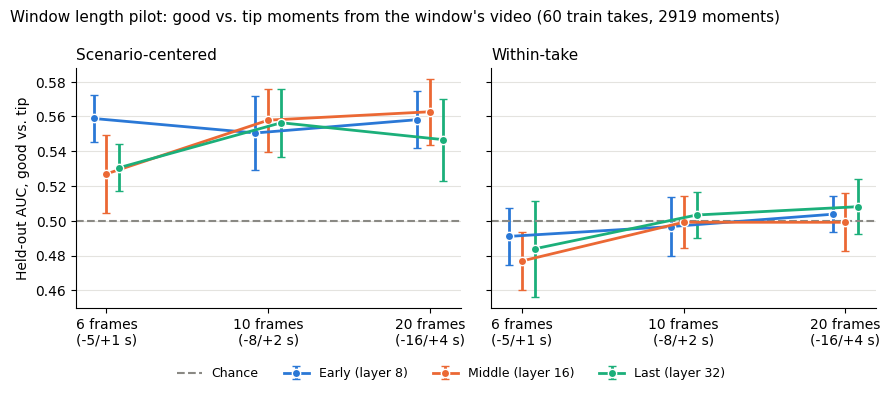

In [5]:
import matplotlib.pyplot as plt

# Held-out good-vs-tip AUC by window length, one panel per centering, layers as series (mean +- sd over folds).
LAYER_COLORS = dict(zip(LAYERS, ("#2a78d6", "#eb6834", "#1baf7a")))
NULL_COLOR, GRID_COLOR, BAND_COLOR = "#8a8984", "#e4e3df", "#e4e3df"

def style(ax):
    ax.grid(axis="y", color=GRID_COLOR, lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
lengths = list(PILOT_WINDOWS)
for ax, (within_take, title) in zip(axes, ((False, "Scenario-centered"), (True, "Within-take"))):
    for k, (name, layer) in enumerate(LAYERS.items()):
        means = [pilot_auc[length, name, within_take].mean() for length in lengths]
        sds = [pilot_auc[length, name, within_take].std() for length in lengths]
        ax.errorbar(np.arange(len(lengths)) + (k - 1) * 0.08, means, yerr=sds, color=LAYER_COLORS[name], lw=2, marker="o",
                    ms=6, markeredgecolor="white", markeredgewidth=1, capsize=3, label=f"{name.capitalize()} (layer {layer})")
    ax.axhline(0.5, color=NULL_COLOR, lw=1.5, ls="--", label="Chance")
    ax.set_xticks(range(len(lengths)), [f"{n} frames\n(-{PILOT_WINDOWS[n][0]}/+{PILOT_WINDOWS[n][1]} s)" for n in lengths])
    ax.set_title(title, loc="left", fontsize=11)
    style(ax)
axes[0].set_ylabel("Held-out AUC, good vs. tip")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, fontsize=9, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.08))
fig.suptitle(f"Window length pilot: good vs. tip moments from the window's video ({N_PILOT_TAKES} train takes, "
             f"{len(pilot_moments)} moments)", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/goodtip_window_pilot.png", dpi=200, bbox_inches="tight")
plt.show()

#### 2. Every moment, and the go/no-go check

Every train and test moment's window (the chosen length) and its tagged text. Then the pilot's check on all train
moments: if the video can't tell good from tip moments of held-out train takes better than chance at any layer,
the moment-level signal isn't in the zero-shot video embeddings, and the notebook stops before the take tiles.

In [6]:
requests = defaultdict(set)
for m in moments:
    requests[m["take_name"]].add(moment_window(m, BEFORE, AFTER))
embed_windows(requests)

TEXT_CACHE = EMBEDDING_DIR / "qwen35_base_goodtip_text.pt"
text_cache = torch.load(TEXT_CACHE) if TEXT_CACHE.exists() else {}
texts = sorted({m["text"] for m in moments} - set(text_cache))
print(f"{len(texts)} texts to embed ({len({m['text'] for m in moments})} distinct)")
for k, text in enumerate(tqdm(texts), 1):
    text_cache[text] = text_embedding(text)
    if k % 1000 == 0:
        torch.save(text_cache, TEXT_CACHE)
torch.save(text_cache, TEXT_CACHE)

0 windows to embed in 0 takes (9552 requested)


0 texts to embed (17709 distinct)


0it [00:00, ?it/s]

In [7]:
train_moments = [m for m in moments if m["split"] == "train"]
test_moments = [m for m in moments if m["split"] == "test"]

def moment_arrays(moment_list, layer_index):
    """Video (window) and text embeddings of the moments at one layer, plus polarity, take and scenario."""
    video = moment_matrix(moment_list, BEFORE, AFTER, layer_index)
    text = np.stack([text_cache[m["text"]][layer_index].double().numpy() for m in moment_list])
    return (video, text, np.array([m["polarity"] for m in moment_list]),
            np.array([m["take_name"] for m in moment_list]), np.array([m["scenario"] for m in moment_list]))

go_auc = {}
for layer_index, name in enumerate(LAYERS):
    video, _, y, takes, scenarios = moment_arrays(train_moments, layer_index)
    for within_take in (False, True):
        go_auc[name, within_take] = polarity_cv_auc(video, y, takes, scenarios, within_take)

print(f"Go/no-go: good vs. tip on held-out train takes ({len(train_moments)} moments, "
      f"{len({m['take_name'] for m in train_moments})} takes), AUC mean (sd over 5 folds)")
for (name, within_take), aucs in go_auc.items():
    print(f"  {name:<8}{'within-take' if within_take else 'scenario-centered':<20}{aucs.mean():.3f} ({aucs.std():.3f})")
# Above chance: the mean AUC is more than 2 standard errors (over folds) above 0.5 somewhere.
GO = any(aucs.mean() - 2 * aucs.std(ddof=1) / np.sqrt(len(aucs)) > 0.5 for aucs in go_auc.values())
print("GO" if GO else "NO-GO: the video doesn't separate good from tip moments; stopping before the take tiles")
assert GO, "no-go"

Go/no-go: good vs. tip on held-out train takes (16567 moments, 371 takes), AUC mean (sd over 5 folds)
  early   scenario-centered   0.629 (0.022)
  early   within-take         0.513 (0.010)
  middle  scenario-centered   0.625 (0.025)
  middle  within-take         0.519 (0.005)
  last    scenario-centered   0.622 (0.023)
  last    within-take         0.513 (0.013)
GO


#### 3. Every take as back-to-back windows

Test takes have no timestamps, so at test time (and for training the proficiency probes, so both see the same kind
of input) each take is cut into back-to-back windows of the chosen length.

In [8]:
embed_windows({take: set(tile_windows(take, WINDOW_FRAMES)) for take in clip_of})

train_take_set = {c["take_name"] for c in clips_by_split["train"]}

def take_tile_means(layer_index):
    """{take: mean of its tiles' embeddings at one layer} and the train tiles' mean per scenario (tile-weighted)."""
    means, scenario_sums = {}, defaultdict(lambda: [0, 0])
    for take, clip in clip_of.items():
        tiles = torch.stack([window_cache[take][w][layer_index] for w in tile_windows(take, WINDOW_FRAMES)]).double().numpy()
        means[take] = tiles.mean(0)
        if clip["take_name"] in train_take_set:
            scenario_sums[clip["scenario"]][0] += tiles.sum(0)
            scenario_sums[clip["scenario"]][1] += len(tiles)
    return means, {s: total / count for s, (total, count) in scenario_sums.items()}

print(f"{sum(len(tile_windows(t, WINDOW_FRAMES)) for t in clip_of)} tiles over {len(clip_of)} takes")

0 windows to embed in 0 takes (7486 requested)
7486 tiles over 1338 takes


#### 4. CCA on the moments

Per layer: scenario means (from the train moments) are subtracted on both sides, each side is reduced to PCA-128 and
CCA fits 32 components on the train moment pairs. Held-out quality comes from 5 folds split by take over the train
takes: each component's correlation on held-out pairs (against a shuffled-pair 95th percentile), how well it separates
good from tip moments (AUC, oriented on the training folds), and its scenario eta². The final fit on all train moments
is then scored on the test moments. The **good minus tip** direction is the mean, over train takes with both, of a
take's mean good window minus its mean tip window.

In [9]:
from sklearn.cross_decomposition import CCA

N_COMPONENTS = 32
PCA_DIMS = 128
N_PERMUTATIONS = 200

def canonical_correlations(a, b):
    a, b = a - a.mean(0), b - b.mean(0)
    return (a * b).sum(0) / np.sqrt((a ** 2).sum(0) * (b ** 2).sum(0))

def scenario_eta2(shared, scenarios):
    within = sum(((shared[scenarios == s] - shared[scenarios == s].mean(0)) ** 2).sum(0) for s in np.unique(scenarios))
    return 1 - within / ((shared - shared.mean(0)) ** 2).sum(0)

def component_auc(shared, y, sign):
    """Good-vs-tip AUC of each canonical variate, oriented by sign (so that good > tip on the data it was fit on)."""
    return np.array([roc_auc_score(y, s * shared[:, k]) for k, s in enumerate(sign)])

def fit_cca(video, text, y, scenarios):
    """Scenario-centered PCA + CCA on moment pairs; the video-side directions in the 2560-d embedding space."""
    keys = np.unique(scenarios)
    video_means = {s: video[scenarios == s].mean(0) for s in keys}
    text_means = {s: text[scenarios == s].mean(0) for s in keys}
    video_c = video - np.stack([video_means[s] for s in scenarios])
    text_c = text - np.stack([text_means[s] for s in scenarios])
    pca_video = PCA(PCA_DIMS, svd_solver="full").fit(video_c)
    pca_text = PCA(PCA_DIMS, svd_solver="full").fit(text_c)
    cca = CCA(n_components=N_COMPONENTS, max_iter=2000).fit(pca_video.transform(video_c), pca_text.transform(text_c))
    video_shared, _ = cca.transform(pca_video.transform(video_c), pca_text.transform(text_c))
    directions = pca_video.components_.T @ (cca.x_rotations_ / cca._x_std[:, None])
    sign = np.sign(video_shared[y == 1].mean(0) - video_shared[y == 0].mean(0))
    return {"video_means": video_means, "text_means": text_means, "pca_video": pca_video, "pca_text": pca_text,
            "cca": cca, "mean": pca_video.mean_, "basis": np.linalg.qr(directions)[0], "sign": sign}

def cca_transform(result, video, text, scenarios):
    """Canonical variates of moment pairs, centered with the fit's scenario means (overall mean for unseen scenarios)."""
    fallback_v = np.mean(list(result["video_means"].values()), 0)
    fallback_t = np.mean(list(result["text_means"].values()), 0)
    video_c = video - np.stack([result["video_means"].get(s, fallback_v) for s in scenarios])
    text_c = text - np.stack([result["text_means"].get(s, fallback_t) for s in scenarios])
    return result["cca"].transform(result["pca_video"].transform(video_c), result["pca_text"].transform(text_c))

def good_minus_tip(video, y, takes):
    """Unit direction: mean over takes with both polarities of (mean good window - mean tip window)."""
    differences = [video[(takes == t) & (y == 1)].mean(0) - video[(takes == t) & (y == 0)].mean(0)
                   for t in np.unique(takes) if ((takes == t) & (y == 1)).any() and ((takes == t) & (y == 0)).any()]
    direction = np.mean(differences, 0)
    return direction / np.linalg.norm(direction)

rng = np.random.default_rng(0)
cca_results, cv_summary, test_summary, moment_level = {}, {}, {}, defaultdict(dict)
for layer_index, (name, layer) in enumerate(tqdm(list(LAYERS.items()))):
    video, text, y, takes, scenarios = moment_arrays(train_moments, layer_index)
    folds = {"r": [], "null": [], "auc": [], "eta2": []}
    for fit, held_out in GroupKFold(5).split(video, y, takes):
        result = fit_cca(video[fit], text[fit], y[fit], scenarios[fit])
        v_shared, t_shared = cca_transform(result, video[held_out], text[held_out], scenarios[held_out])
        folds["r"].append(canonical_correlations(v_shared, t_shared))
        folds["null"].append(np.quantile([canonical_correlations(v_shared, t_shared[rng.permutation(len(t_shared))])
                                          for _ in range(N_PERMUTATIONS)], 0.95, axis=0))
        folds["auc"].append(component_auc(v_shared, y[held_out], result["sign"]))
        folds["eta2"].append(scenario_eta2(v_shared, scenarios[held_out]))
    cv_summary[name] = {key: np.mean(values, 0) for key, values in folds.items()}

    result = cca_results[name] = fit_cca(video, text, y, scenarios)
    result["polarity_component"] = int(np.argmax(cv_summary[name]["auc"]))  # chosen on the train folds only
    result["good_minus_tip"] = good_minus_tip(video, y, takes)
    t_video, t_text, t_y, t_takes, t_scenarios = moment_arrays(test_moments, layer_index)
    v_shared, t_shared = cca_transform(result, t_video, t_text, t_scenarios)
    test_summary[name] = {"r": canonical_correlations(v_shared, t_shared),
                          "auc": component_auc(v_shared, t_y, result["sign"])}

    # Moment-level good vs. tip on the test moments: the CCA polarity component, the good-minus-tip direction, and a
    # logistic probe on the whole window embedding (fit on all train moments), each scenario-centered and within-take.
    for within_take in (False, True):
        label = "within-take" if within_take else "scenario-centered"
        all_video = np.concatenate([video, t_video])
        all_keys = np.concatenate([takes, t_takes]) if within_take else np.concatenate([scenarios, t_scenarios])
        fit_rows = np.ones(len(all_video), bool) if within_take else np.arange(len(all_video)) < len(video)
        all_c = centered(all_video, all_keys, fit_rows)
        train_c, test_c = all_c[:len(video)], all_c[len(video):]
        probe = polarity_probe()
        probe.set_params(logisticregressioncv__cv=list(GroupKFold(3).split(train_c, groups=takes)))
        probe.fit(train_c, y)
        k = result["polarity_component"]
        component = (test_c - result["mean"]) @ (result["pca_video"].components_.T @ (result["cca"].x_rotations_[:, k] / result["cca"]._x_std))
        moment_level[name][label] = {
            "probe on full window": roc_auc_score(t_y, probe.predict_proba(test_c)[:, 1]),
            f"CCA component {k + 1}": roc_auc_score(t_y, result["sign"][k] * component),
            "good minus tip": roc_auc_score(t_y, test_c @ result["good_minus_tip"]),
        }

print(f"CCA on {len(train_moments)} train moment pairs; held-out = 5 folds by take; test = {len(test_moments)} test moments\n")
for name, layer in LAYERS.items():
    cv, test = cv_summary[name], test_summary[name]
    above = int((cv["r"] > cv["null"]).sum())
    print(f"{name} (layer {layer}): {above}/{N_COMPONENTS} components above the shuffled 95th percentile (held-out folds)")
    print("  component          " + "".join(f"{k:>6}" for k in range(1, 11)))
    print("  held-out r         " + "".join(f"{r:>6.2f}" for r in cv["r"][:10]))
    print("  test r             " + "".join(f"{r:>6.2f}" for r in test["r"][:10]))
    print("  held-out good AUC  " + "".join(f"{a:>6.2f}" for a in cv["auc"][:10]))
    print("  test good AUC      " + "".join(f"{a:>6.2f}" for a in test["auc"][:10]))
    print("  scenario eta2      " + "".join(f"{e:>6.2f}" for e in cv["eta2"][:10]))
    k = cca_results[name]["polarity_component"]
    print(f"  most polar component (held-out folds): {k + 1}, held-out AUC {cv['auc'][k]:.3f}, test AUC {test['auc'][k]:.3f}")
print("\nGood vs. tip on the test moments (AUC)")
for name, by_centering in moment_level.items():
    for label, aucs in by_centering.items():
        print(f"  {name:<8}{label:<20}" + "  ".join(f"{method} {auc:.3f}" for method, auc in aucs.items()))

  0%|          | 0/3 [00:00<?, ?it/s]

CCA on 16567 train moment pairs; held-out = 5 folds by take; test = 2476 test moments

early (layer 8): 32/32 components above the shuffled 95th percentile (held-out folds)
  component               1     2     3     4     5     6     7     8     9    10
  held-out r           0.74  0.63  0.62  0.55  0.39  0.41  0.48  0.41  0.45  0.46
  test r               0.76  0.62  0.63  0.59  0.48  0.29  0.44  0.35  0.20  0.34
  held-out good AUC    0.53  0.51  0.52  0.50  0.54  0.54  0.52  0.53  0.52  0.51
  test good AUC        0.50  0.49  0.49  0.52  0.53  0.50  0.53  0.49  0.53  0.48
  scenario eta2        0.05  0.01  0.09  0.04  0.04  0.09  0.03  0.04  0.07  0.05
  most polar component (held-out folds): 16, held-out AUC 0.563, test AUC 0.490
middle (layer 16): 31/32 components above the shuffled 95th percentile (held-out folds)
  component               1     2     3     4     5     6     7     8     9    10
  held-out r           0.73  0.59  0.51  0.45  0.36  0.43  0.36  0.32  0.35  0.27
  t

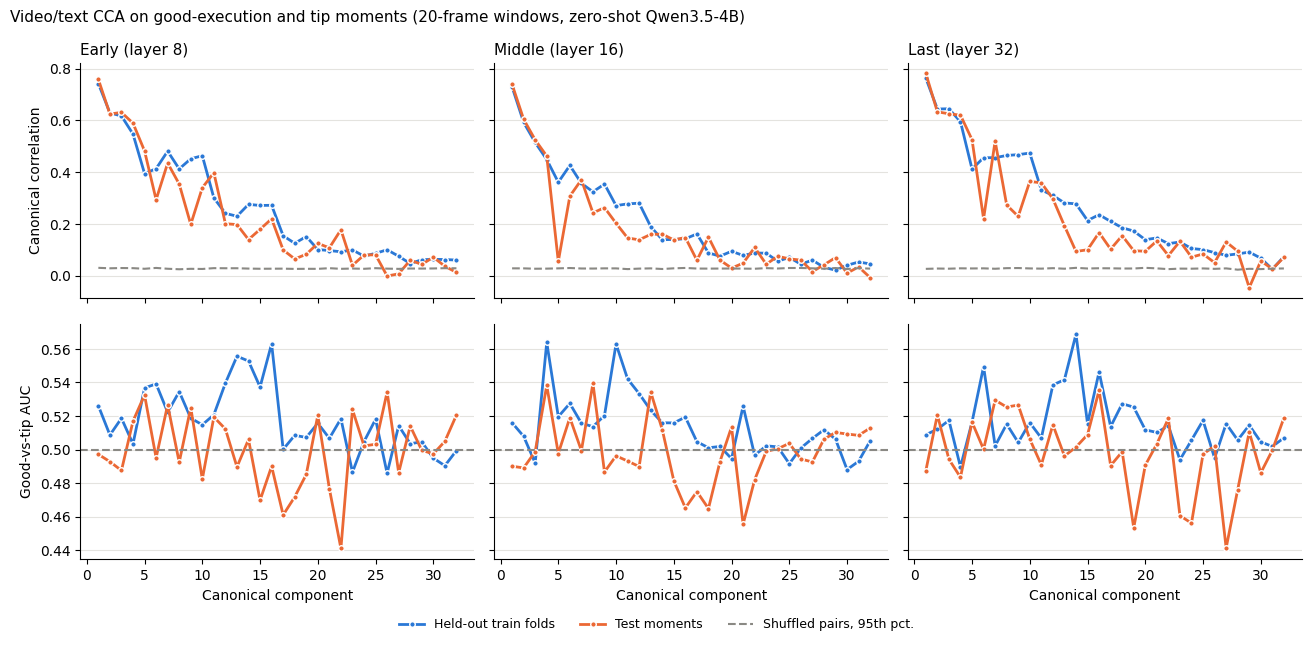

In [10]:
# Per component: held-out canonical correlation (with the shuffled 95th percentile) and held-out good-vs-tip AUC.
components = np.arange(1, N_COMPONENTS + 1)
fig, axes = plt.subplots(2, len(LAYERS), figsize=(4.4 * len(LAYERS), 6.2), sharex=True, sharey="row")
for col, (name, layer) in enumerate(LAYERS.items()):
    cv, test = cv_summary[name], test_summary[name]
    ax = axes[0, col]
    ax.plot(components, cv["r"], color="#2a78d6", lw=2, marker="o", ms=4, markeredgecolor="white", label="Held-out train folds")
    ax.plot(components, test["r"], color="#eb6834", lw=2, marker="o", ms=4, markeredgecolor="white", label="Test moments")
    ax.plot(components, cv["null"], color=NULL_COLOR, lw=1.5, ls="--", label="Shuffled pairs, 95th pct.")
    ax.set_title(f"{name.capitalize()} (layer {layer})", loc="left", fontsize=11)
    style(ax)
    ax = axes[1, col]
    ax.plot(components, cv["auc"], color="#2a78d6", lw=2, marker="o", ms=4, markeredgecolor="white")
    ax.plot(components, test["auc"], color="#eb6834", lw=2, marker="o", ms=4, markeredgecolor="white")
    ax.axhline(0.5, color=NULL_COLOR, lw=1.5, ls="--")
    ax.set_xlabel("Canonical component")
    style(ax)
axes[0, 0].set_ylabel("Canonical correlation")
axes[1, 0].set_ylabel("Good-vs-tip AUC")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, fontsize=9, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.04))
fig.suptitle(f"Video/text CCA on good-execution and tip moments ({WINDOW_FRAMES}-frame windows, zero-shot Qwen3.5-4B)",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig("figures/goodtip_cca_components.png", dpi=200, bbox_inches="tight")
plt.show()

#### 5. Proficiency probes

Each take's feature is the mean of its tile embeddings minus the train tiles' mean for its scenario, then projected
like this: **full** (no projection), **shared** (onto the moment CCA's 32 video directions), **residual** (the rest),
**PCA-128** / **top-32 PCA** (the CCA's video PCA), **random** 32-d subspaces of the PCA-128 space (10 draws),
**good minus tip** (the one score along that direction), and as a reference the **continuous 160-frame** embedding
from `continuous_sampling.ipynb` (zero-shot, scenario-centered the same way). Since the centering removes scenario,
every probe also gets the scenario one-hot, and **scenario only** is the baseline to beat. Logistic regression,
regularization by 5-fold CV on train, as before.

In [11]:
from scipy.stats import spearmanr
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.preprocessing import OneHotEncoder

N_RANDOM_SUBSPACES = 10
train_takes = [c["take_name"] for c in clips_by_split["train"]]
test_take_names = [c["take_name"] for c in clips]
train_scores = np.array([c["score"] for c in clips_by_split["train"]])
test_scores = np.array([c["score"] for c in clips])
scenario_encoder = OneHotEncoder(handle_unknown="ignore").fit([[c["scenario"]] for c in clips_by_split["train"]])
scenario_onehot = {split: scenario_encoder.transform([[c["scenario"]] for c in clips_by_split[split]]).toarray()
                   for split in ("train", "test")}

def probe(train_x, test_x):
    """Test predictions of a logistic probe on [scenario one-hot, features], trained on the train takes."""
    model = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=np.logspace(-4, 2, 13), cv=5, max_iter=5000, n_jobs=-1))
    model.fit(np.hstack([scenario_onehot["train"], train_x]), train_scores)
    return model.predict(np.hstack([scenario_onehot["test"], test_x]))

def project(x, result, basis):
    return (x - result["mean"]) @ basis @ basis.T

continuous = {split: torch.load(EMBEDDING_DIR / f"qwen35_continuous{WINDOW_FPS}fps160_{split}_raw.pt") for split in ("train", "test")}

predictions = {"scenario only": probe(np.zeros((len(train_takes), 0)), np.zeros((len(test_take_names), 0)))}
majority = np.bincount(train_scores).argmax()
predictions["majority class"] = np.full_like(test_scores, majority)
train_scenarios = np.array([c["scenario"] for c in clips_by_split["train"]])
scenario_majority = {s: np.bincount(train_scores[train_scenarios == s]).argmax() for s in np.unique(train_scenarios)}
predictions["per-scenario majority"] = np.array([scenario_majority[c["scenario"]] for c in clips])

goodness = {}
for layer_index, (name, layer) in enumerate(tqdm(list(LAYERS.items()))):
    result = cca_results[name]
    tile_means, scenario_means = take_tile_means(layer_index)
    fallback = np.mean(list(scenario_means.values()), 0)
    features = {split: np.stack([tile_means[c["take_name"]] - scenario_means.get(c["scenario"], fallback)
                                 for c in clips_by_split[split]]) for split in ("train", "test")}
    train_x, test_x = features["train"], features["test"]
    key = f"{name} (layer {layer})"
    predictions[f"{key}: full"] = probe(train_x, test_x)
    shared = {split: project(x, result, result["basis"]) for split, x in features.items()}
    predictions[f"{key}: shared"] = probe(shared["train"], shared["test"])
    predictions[f"{key}: residual"] = probe(train_x - result["mean"] - shared["train"], test_x - result["mean"] - shared["test"])
    pca_basis = result["pca_video"].components_.T
    predictions[f"{key}: pca128"] = probe(project(train_x, result, pca_basis), project(test_x, result, pca_basis))
    predictions[f"{key}: pca32"] = probe(project(train_x, result, pca_basis[:, :N_COMPONENTS]),
                                         project(test_x, result, pca_basis[:, :N_COMPONENTS]))
    for seed in range(N_RANDOM_SUBSPACES):
        basis = pca_basis @ np.linalg.qr(np.random.default_rng(seed).standard_normal((PCA_DIMS, N_COMPONENTS)))[0]
        predictions[f"{key}: random {seed}"] = probe(project(train_x, result, basis), project(test_x, result, basis))
    goodness[name] = {split: x @ result["good_minus_tip"] for split, x in features.items()}
    predictions[f"{key}: good minus tip"] = probe(goodness[name]["train"][:, None], goodness[name]["test"][:, None])

    reference = {split: np.stack([continuous[split][c["take_name"]]["base"][layer - 1].double().numpy()
                                  for c in clips_by_split[split]]) for split in ("train", "test")}
    reference_means = {s: reference["train"][train_scenarios == s].mean(0) for s in np.unique(train_scenarios)}
    reference_c = {split: reference[split] - np.stack([reference_means[c["scenario"]] for c in clips_by_split[split]])
                   for split in ("train", "test")}
    predictions[f"{key}: continuous 160"] = probe(reference_c["train"], reference_c["test"])

print("Label-free: Spearman correlation of a take's mean good-minus-tip score with its proficiency level")
covered_test = np.array([t in covered for t in test_take_names])
for name in LAYERS:
    rho_train = spearmanr(goodness[name]["train"], train_scores)
    rho_test = spearmanr(goodness[name]["test"], test_scores)
    rho_covered = spearmanr(goodness[name]["test"][covered_test], test_scores[covered_test])
    print(f"  {name:<8} train {rho_train.statistic:+.3f} (p {rho_train.pvalue:.2g})   test {rho_test.statistic:+.3f} "
          f"(p {rho_test.pvalue:.2g})   test takes with moments {rho_covered.statistic:+.3f} (p {rho_covered.pvalue:.2g})")

  0%|          | 0/3 [00:00<?, ?it/s]

Label-free: Spearman correlation of a take's mean good-minus-tip score with its proficiency level
  early    train +0.049 (p 0.093)   test +0.018 (p 0.82)   test takes with moments +0.007 (p 0.96)
  middle   train +0.025 (p 0.39)   test -0.025 (p 0.75)   test takes with moments -0.073 (p 0.57)
  last     train +0.143 (p 8.5e-07)   test +0.074 (p 0.34)   test takes with moments -0.011 (p 0.94)


In [12]:
# Accuracy per subgroup of test takes, with 95% bootstrap intervals (1,000 resamples of test takes) for the accuracies
# and for shared minus full / shared minus random (the mean over the random draws).
N_BOOTSTRAP = 1000
participants_train = {c["participant"] for c in clips_by_split["train"]}
SUBGROUPS = {
    "All": np.ones(len(clips), bool),
    "With moments": covered_test,
    "Rock Climbing": np.array([c["scenario"] == "Rock Climbing" for c in clips]),
    "Participant in train": np.array([c["participant"] in participants_train for c in clips]),
    "New participant": np.array([c["participant"] not in participants_train for c in clips]),
}
PARTS = {"full": "Full", "shared": "Shared (CCA)", "residual": "Residual", "pca128": "PCA-128", "pca32": "Top-32 PCA",
         "random": "Random 32-d in PCA-128", "good minus tip": "Good minus tip", "continuous 160": "Continuous 160 (reference)"}
boot = np.random.default_rng(0)
resamples = {group: [boot.choice(np.flatnonzero(rows), rows.sum()) for _ in range(N_BOOTSTRAP)] for group, rows in SUBGROUPS.items()}

def correct(key):
    """(test takes,) 1 where the prediction is right; "random" averages over the random-subspace draws."""
    if key.endswith(": random"):
        return np.mean([predictions[f"{key} {seed}"] == test_scores for seed in range(N_RANDOM_SUBSPACES)], 0)
    return (predictions[key] == test_scores).astype(float)

def interval(values):
    return np.quantile(values, [0.025, 0.975])

summary = {}
for group, rows in SUBGROUPS.items():
    for key in ["majority class", "per-scenario majority", "scenario only"] + [
            f"{name} (layer {layer}): {part}" for name, layer in LAYERS.items() for part in PARTS]:
        hits = correct(key)
        summary[group, key] = (hits[rows].mean(), interval([hits[r].mean() for r in resamples[group]]))

print(f"Proficiency probes ({len(train_takes)} train takes); test accuracy [95% bootstrap interval]\n")
print(f"{'features':<36}" + "".join(f"{f'{group} ({rows.sum()})':>26}" for group, rows in SUBGROUPS.items()))
for key in ["majority class", "per-scenario majority", "scenario only"] + [
        f"{name} (layer {layer}): {part}" for name, layer in LAYERS.items() for part in PARTS]:
    print(f"{key:<36}" + "".join(f"{summary[group, key][0]:>10.3f} [{summary[group, key][1][0]:.3f}, {summary[group, key][1][1]:.3f}]"
                                  for group in SUBGROUPS))
print("\nShared minus full / shared minus random, accuracy difference [95% bootstrap interval]")
for name, layer in LAYERS.items():
    key = f"{name} (layer {layer})"
    shared = correct(f"{key}: shared")
    for other in ("full", "random"):
        diff = shared - correct(f"{key}: {other}")
        print(f"  {key:<20} vs {other:<8}" + "".join(
            f"{f'{group}':>16} {diff[rows].mean():+.3f} [{interval([diff[r].mean() for r in resamples[group]])[0]:+.3f}, "
            f"{interval([diff[r].mean() for r in resamples[group]])[1]:+.3f}]" for group, rows in SUBGROUPS.items()))

balanced = {key: balanced_accuracy_score(test_scores, predictions[key]) for key in predictions if " random " not in key}
print("\nBalanced accuracy, all test takes: " + ", ".join(f"{key} {value:.3f}" for key, value in balanced.items()
                                                       if not key.endswith(("pca128", "pca32", "residual"))))

latex_groups = ("All", "With moments", "Rock Climbing")
latex = [
    r"\begin{table}[t]", r"\centering", r"\small",
    r"\caption{Test accuracy of proficiency probes on zero-shot Qwen3.5-4B ego video. Each take is the mean of "
    rf"back-to-back {WINDOW_FRAMES}-frame 1~FPS windows, scenario-centered; every probe also gets the scenario one-hot. "
    r"Shared: projection onto the 32 video directions of a CCA between windows around good-execution / "
    r"tip-for-improvement moments and the experts' tagged text for them; residual: the remainder; good minus tip: the "
    r"score along the mean difference between a take's good and tip windows; continuous 160: the 160-frame window "
    rf"embedding of the earlier experiment. With moments: the {covered_test.sum()} test takes that have moment "
    r"annotations; Rock Climbing has none.}",
    r"\label{tab:goodtip-probes}", r"\begin{tabular}{ll" + "c" * len(latex_groups) + "}", r"\toprule",
    r"Layer & Representation & " + " & ".join(f"{g} ({SUBGROUPS[g].sum()})" for g in latex_groups) + r" \\", r"\midrule",
]
for k, (name, layer) in enumerate(LAYERS.items()):
    if k:
        latex.append(r"\midrule")
    for j, (part, label) in enumerate(PARTS.items()):
        latex.append(f"{layer if j == 0 else ''} & {label} & "
                     + " & ".join(f"{summary[g, f'{name} (layer {layer}): {part}'][0]:.3f}" for g in latex_groups) + r" \\")
latex.append(r"\midrule")
for baseline in ("majority class", "per-scenario majority", "scenario only"):
    latex.append(f"{baseline.capitalize()} & & " + " & ".join(f"{summary[g, baseline][0]:.3f}" for g in latex_groups) + r" \\")
latex += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
print("\n" + "\n".join(latex))

Proficiency probes (1174 train takes); test accuracy [95% bootstrap interval]

features                                             All (164)         With moments (61)        Rock Climbing (51) Participant in train (47)     New participant (117)
majority class                           0.354 [0.280, 0.427]     0.557 [0.443, 0.672]     0.235 [0.137, 0.353]     0.468 [0.340, 0.617]     0.308 [0.231, 0.393]
per-scenario majority                    0.433 [0.360, 0.506]     0.672 [0.557, 0.787]     0.392 [0.275, 0.529]     0.319 [0.191, 0.468]     0.479 [0.385, 0.564]
scenario only                            0.433 [0.360, 0.506]     0.672 [0.557, 0.787]     0.392 [0.275, 0.529]     0.319 [0.191, 0.468]     0.479 [0.385, 0.564]
early (layer 8): full                    0.409 [0.335, 0.488]     0.492 [0.377, 0.607]     0.294 [0.176, 0.412]     0.340 [0.213, 0.468]     0.436 [0.342, 0.521]
early (layer 8): shared                  0.457 [0.384, 0.530]     0.541 [0.410, 0.656]     0.431 [0.294, 0

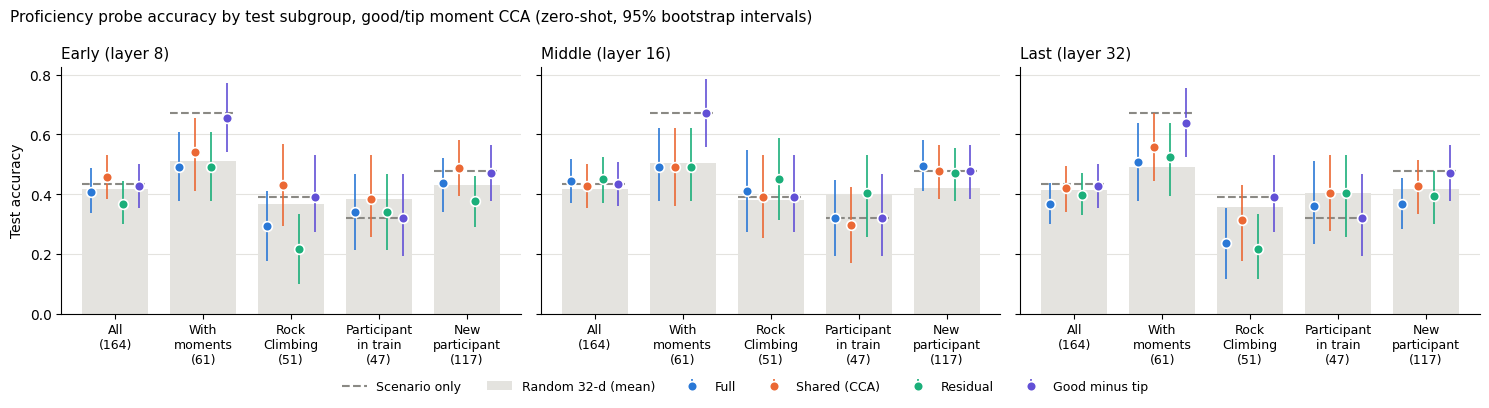

In [13]:
# Test accuracy per subgroup: full / shared / residual / good minus tip as dots with 95% bootstrap intervals, the
# random-subspace mean as a gray bar, and scenario only as a dashed tick.
PART_COLORS = {"full": "#2a78d6", "shared": "#eb6834", "residual": "#1baf7a", "good minus tip": "#6250d6"}
groups = list(SUBGROUPS)
x = np.arange(len(groups))
offsets = dict(zip(PART_COLORS, np.linspace(-0.27, 0.27, len(PART_COLORS))))
fig, axes = plt.subplots(1, len(LAYERS), figsize=(5.0 * len(LAYERS), 3.8), sharey=True)
for ax, (name, layer) in zip(axes, LAYERS.items()):
    key = f"{name} (layer {layer})"
    ax.bar(x, [summary[g, f"{key}: random"][0] for g in groups], width=0.75, color=BAND_COLOR, label="Random 32-d (mean)")
    for k, g in enumerate(groups):
        ax.plot([k - 0.375, k + 0.375], [summary[g, "scenario only"][0]] * 2, color=NULL_COLOR, lw=1.5, ls="--",
                label="Scenario only" if k == 0 else None)
    for part, color in PART_COLORS.items():
        values = np.array([summary[g, f"{key}: {part}"][0] for g in groups])
        bounds = np.array([summary[g, f"{key}: {part}"][1] for g in groups])
        ax.errorbar(x + offsets[part], values, yerr=[values - bounds[:, 0], bounds[:, 1] - values], ls="none", marker="o",
                    ms=7, color=color, markeredgecolor="white", markeredgewidth=1.2, elinewidth=1.2, capsize=0, label=PARTS[part])
    ax.set_xticks(x, [f"{g.replace(' ', chr(10), 1)}\n({SUBGROUPS[g].sum()})" for g in groups], fontsize=9)
    ax.set_title(f"{name.capitalize()} (layer {layer})", loc="left", fontsize=11)
    style(ax)
axes[0].set_ylabel("Test accuracy")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, fontsize=9, ncol=len(labels), loc="lower center", bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Proficiency probe accuracy by test subgroup, good/tip moment CCA (zero-shot, 95% bootstrap intervals)",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig("figures/goodtip_probe_accuracy.png", dpi=200, bbox_inches="tight")
plt.show()

#### 6. Checks: participant leakage and overlapping labels

Two reasons the go/no-go AUC (0.62 scenario-centered, about 0.51 within-take, about 0.51 on test moments) could
mislead:

* **Participant leakage.** Folds split by take put other takes of the same person in training. If people differ in
  how many good executions they get, the probe can learn the person rather than the moment. Check: the label-only
  score (each held-out moment scored by its participant's good share in the training folds), and the video probe
  again with folds split by participant.
* **Overlapping labels.** Experts often say "good X, but Y" at one pause, so good and tip moments of a take can share
  their window. Check: distance from each moment to the nearest opposite-polarity moment of its take, and the
  within-take probe on the **clean** moments (none within 20 s, in takes that keep both polarities).

In [14]:
y_train, takes_train, scenarios_train = (np.array([m[k] for m in train_moments]) for k in ("polarity", "take_name", "scenario"))
participants_moment = np.array([clip_of[t]["participant"] for t in takes_train])

def cv_auc_by(X, groups, within_take, rows=None):
    """polarity_cv_auc with folds (and the probe's inner CV) split by `groups`; optionally on a subset of rows."""
    rows = np.ones(len(y_train), bool) if rows is None else rows
    X, y, takes, scenarios, groups = X[rows], y_train[rows], takes_train[rows], scenarios_train[rows], np.asarray(groups)[rows]
    if within_take:
        X = centered(X, takes, np.ones(len(X), bool))
    aucs = []
    for fit, held_out in GroupKFold(5).split(X, y, groups):
        fit_rows = np.zeros(len(X), bool)
        fit_rows[fit] = True
        Xc = X if within_take else centered(X, scenarios, fit_rows)
        probe = polarity_probe()
        probe.set_params(logisticregressioncv__cv=list(GroupKFold(3).split(fit, groups=groups[fit])))
        probe.fit(Xc[fit], y[fit])
        aucs.append(roc_auc_score(y[held_out], probe.predict_proba(Xc[held_out])[:, 1]))
    return np.array(aucs)

def fmt(aucs):
    return f"{aucs.mean():.3f} ± {2 * aucs.std(ddof=1) / np.sqrt(len(aucs)):.3f}"

# Label-only leakage: score each held-out moment by its participant's good share in the training folds.
print("Label only (no video): held-out moments scored by their participant's good share in the training folds, AUC")
for fold_name, groups in (("take", takes_train), ("participant", participants_moment)):
    aucs = []
    for fit, held_out in GroupKFold(5).split(y_train, y_train, groups):
        share = defaultdict(list)
        for i in fit:
            share[participants_moment[i]].append(y_train[i])
        prior = y_train[fit].mean()
        aucs.append(roc_auc_score(y_train[held_out], [np.mean(share[participants_moment[i]]) if share[participants_moment[i]]
                                                      else prior for i in held_out]))
    print(f"  folds by {fold_name:<12} {fmt(np.array(aucs))}")

# Distance to the nearest opposite-polarity moment of the same take.
nearest = np.full(len(train_moments), np.inf)
for take in np.unique(takes_train):
    rows = np.flatnonzero(takes_train == take)
    times = np.array([train_moments[i]["time"] for i in rows])
    for j, i in enumerate(rows):
        other = times[y_train[rows] != y_train[i]]
        if len(other):
            nearest[i] = np.abs(other - times[j]).min()
window_of = [moment_window(m, BEFORE, AFTER) for m in train_moments]
same_window = np.array([any(y_train[j] != y_train[i] and window_of[j] == window_of[i]
                            for j in np.flatnonzero(takes_train == takes_train[i])) for i in range(len(train_moments))])
print("\nTrain moments with an opposite-polarity moment of the same take within d seconds:")
print("  " + "   ".join(f"{d} s: {np.mean(nearest <= d):.2f}" for d in (0, 1, 2, 5, 10, 20)))
print(f"  sharing their exact {WINDOW_FRAMES}-frame window with an opposite moment: {same_window.mean():.2f}")

CLEAN_SECONDS = BEFORE + AFTER
clean = nearest > CLEAN_SECONDS
both = {t for t in np.unique(takes_train[clean]) if len(set(y_train[clean & (takes_train == t)])) == 2}
clean &= np.isin(takes_train, list(both))
print(f"  clean (none within {CLEAN_SECONDS} s, takes keeping both): {clean.sum()} moments in {len(both)} takes")

print("\nVideo probe, good vs. tip on held-out train moments, AUC mean ± 2 se over 5 folds")
check_auc = {}
for layer_index, (name, layer) in enumerate(LAYERS.items()):
    X = moment_matrix(train_moments, BEFORE, AFTER, layer_index)
    for within_take in (False, True):
        label = "within-take" if within_take else "scenario-centered"
        check_auc[name, label, "take"] = cv_auc_by(X, takes_train, within_take)
        check_auc[name, label, "participant"] = cv_auc_by(X, participants_moment, within_take)
        print(f"  {name:<7}{label:<19} folds by take {fmt(check_auc[name, label, 'take'])}   "
              f"by participant {fmt(check_auc[name, label, 'participant'])}")
    check_auc[name, "clean"] = cv_auc_by(X, participants_moment, True, clean)
    print(f"  {name:<7}{'within-take, clean':<19} by participant {fmt(check_auc[name, 'clean'])}")

Label only (no video): held-out moments scored by their participant's good share in the training folds, AUC


  folds by take         0.639 ± 0.033
  folds by participant  0.500 ± 0.000



Train moments with an opposite-polarity moment of the same take within d seconds:
  0 s: 0.37   1 s: 0.60   2 s: 0.67   5 s: 0.78   10 s: 0.87   20 s: 0.93
  sharing their exact 20-frame window with an opposite moment: 0.58
  clean (none within 20 s, takes keeping both): 482 moments in 56 takes

Video probe, good vs. tip on held-out train moments, AUC mean ± 2 se over 5 folds


  early  scenario-centered   folds by take 0.629 ± 0.022   by participant 0.605 ± 0.021


  early  within-take         folds by take 0.513 ± 0.010   by participant 0.514 ± 0.014


  early  within-take, clean  by participant 0.577 ± 0.065


... (2 outputs left out)

  middle within-take, clean  by participant 0.580 ± 0.068


  last   scenario-centered   folds by take 0.622 ± 0.023   by participant 0.601 ± 0.024


  last   within-take         folds by take 0.513 ± 0.013   by participant 0.519 ± 0.009


  last   within-take, clean  by participant 0.578 ± 0.071
